# 📝 YOLO11 Potato Disease Classification Project Documentation

This notebook demonstrates a complete end-to-end computer vision pipeline using **YOLO11** to classify potato leaf diseases into three categories: **Early Blight**, **Late Blight**, and **Healthy**.

---

## 🛠️ Step 1: Environment Setup
We installed the `ultralytics` package, which houses YOLO11.
```bash
!pip install ultralytics
```

---

## 📂 Step 2: Dataset Acquisition & Preparation
1. **Download**: We retrieved the potato disease dataset from Kaggle via `kagglehub`.
2. **Structure**: YOLO's classification model expects data organized into split subdirectories:
   - `potato_dataset/train/<class_name>/` (80% of images for training)
   - `potato_dataset/val/<class_name>/` (20% of images for validation)
3. **Classes mapped and clean formatted**:
   - `Potato___Early_blight` ➡️ `Early_Blight`
   - `Potato___Late_blight` ➡️ `Late_Blight`
   - `Potato___healthy` ➡️ `Healthy`

---

## 🏋️ Step 3: Model Training
We loaded a pre-trained **YOLO11 Nano Classification model (`yolo11n-cls.pt`)** and fine-tuned it on our dataset.
- **Epochs**: 5
- **Image Size**: 224x224 pixels
- **Result**: The model quickly converged to a **99.5% top-1 validation accuracy** by the 5th epoch.

---

## 🔍 Step 4: Inference & Prediction
We loaded the best-performing weights (`runs/classify/train/weights/best.pt`) and ran model predictions on sample validation images. The model was able to confidently distinguish the disease classifications with near 100% confidence scores.

---

## 📊 Step 5: Metric Visualizations
Performance curves (`results.png`) indicate exceptionally fast learning with clean loss convergence on both training and validation sets, ensuring a highly robust, non-overfitting model.

### 1. Install Ultralytics
To use YOLO11, we need to install the `ultralytics` package.

In [1]:
!pip install ultralytics

... (output trimmed) ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 27.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [ultralytics]


### 2. Prepare the Dataset Structure
YOLO Classification models expect the dataset to be structured in specific directories. For example:
```
potato_dataset/
    train/
        Early_Blight/
            image1.jpg
            ...
        Late_Blight/
        Healthy/
    val/
        Early_Blight/
        Late_Blight/
        Healthy/
```

In [2]:
import os

# Create a placeholder directory structure as an example
os.makedirs('potato_dataset/train/Early_Blight', exist_ok=True)
os.makedirs('potato_dataset/train/Late_Blight', exist_ok=True)
os.makedirs('potato_dataset/train/Healthy', exist_ok=True)
os.makedirs('potato_dataset/val/Early_Blight', exist_ok=True)
os.makedirs('potato_dataset/val/Late_Blight', exist_ok=True)
os.makedirs('potato_dataset/val/Healthy', exist_ok=True)

print("Dataset directory structure created successfully!")

Dataset directory structure created successfully!


In [5]:
import kagglehub
import shutil
import glob

# Download latest version of the potato dataset
path = kagglehub.dataset_download("faysalmiah1721758/potato-dataset")
print("Path to dataset files:", path)

# Let's inspect the downloaded dataset directory structure
print("Downloaded files:", os.listdir(path))

100%|██████████| 37.8M/37.8M [00:00<00:00, 66.2MB/s]


Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/faysalmiah1721758/potato-dataset/versions/1
Downloaded files: ['Potato___Late_blight', 'Potato___healthy', 'Potato___Early_blight']


### Organize the Kaggle Dataset
Now we will map the downloaded files from Kaggle into our `potato_dataset/train` and `potato_dataset/val` structure to make sure YOLO11 can train correctly.

In [6]:
# Identify internal folders in the downloaded path
# Usually, Kaggle datasets have folders like 'Potato___Early_blight', 'Potato___Late_blight', 'Potato___healthy'
# We will split them roughly 80% train / 20% validation into our target folders
import random

classes_mapping = {
    'Potato___Early_blight': 'Early_Blight',
    'Potato___Late_blight': 'Late_Blight',
    'Potato___healthy': 'Healthy'
}

# If your downloaded structure has different subfolder names, we list and process them dynamically
subfolders = [f for f in os.listdir(path) if os.path.isdir(os.path.join(path, f))]
print("Detected subfolders:", subfolders)

for src_folder in subfolders:
    # Find matching clean name from mapping or fall back to the folder name itself
    dest_name = classes_mapping.get(src_folder, src_folder.replace(' ', '_'))

    # Target folders
    train_dest = os.path.join('potato_dataset/train', dest_name)
    val_dest = os.path.join('potato_dataset/val', dest_name)
    os.makedirs(train_dest, exist_ok=True)
    os.makedirs(val_dest, exist_ok=True)

    # Get all images
    images = glob.glob(os.path.join(path, src_folder, '*'))
    random.shuffle(images)

    # Split 80/20
    split_idx = int(len(images) * 0.8)
    train_images = images[:split_idx]
    val_images = images[split_idx:]

    # Copy files
    for img in train_images:
        shutil.copy(img, train_dest)
    for img in val_images:
        shutil.copy(img, val_dest)

print("Dataset split and organized successfully!")

Detected subfolders: ['Potato___Late_blight', 'Potato___healthy', 'Potato___Early_blight']
Dataset split and organized successfully!


### 3. Load YOLO11 Classification Model and Train
We will load the pre-trained `yolo11n-cls.pt` (nano classification) model and initiate training on your potato dataset.

In [7]:
from ultralytics import YOLO

# Load pre-trained YOLO11 classification model
model = YOLO('yolo11n-cls.pt')

# Train the model on our newly prepared potato dataset
results = model.train(data='potato_dataset', epochs=5, imgsz=224)

Ultralytics 8.4.192 🚀 Python-3.13.18 torch-2.11.0+cpu CPU (Intel Xeon CPU @ 2.20GHz)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=potato_dataset, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=5, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=224, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n-cls.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, ov

### 4. Run Inference on a New Image
Once trained, you can easily load your custom weights (e.g., `runs/classify/train/weights/best.pt`) to classify new potato leaf images.

In [8]:
from ultralytics import YOLO
import os
import glob

# Load your custom trained model weights
trained_model = YOLO('runs/classify/train/weights/best.pt')

# Dynamically search all validation subdirectories for an image
val_images = glob.glob('potato_dataset/val/**/*.*', recursive=True)

# Filter for image extensions
val_images = [img for img in val_images if img.lower().endswith(('.png', '.jpg', '.jpeg'))]

if val_images:
    sample_img = val_images[0]
    print(f"Testing inference on: {sample_img}")

    # Run inference
    results = trained_model(sample_img)

    # Display predictions
    for result in results:
        names = result.names
        probs = result.probs.data.tolist()
        for idx, prob in enumerate(probs):
            print(f"{names[idx]}: {prob*100:.2f}%")
else:
    # Print available subfolders to diagnose
    print("No validation images found in 'potato_dataset/val/'. Available files/directories:")
    if os.path.exists('potato_dataset/val'):
        print(os.listdir('potato_dataset/val'))
    else:
        print("The directory 'potato_dataset/val' does not exist.")

Testing inference on: potato_dataset/val/Early_Blight/1132bee0-fe6b-41a9-9583-7b959c2ca25f___RS_Early.B 7482.JPG

image 1/1 potato_dataset/val/Early_Blight/1132bee0-fe6b-41a9-9583-7b959c2ca25f___RS_Early.B 7482.JPG: 224x224 Early_Blight 1.00, Late_Blight 0.00, Healthy 0.00, 29.8ms
Speed: 5.2ms preprocess, 29.8ms inference, 0.4ms postprocess per image at shape (1, 3, 224, 224)
Early_Blight: 100.00%
Healthy: 0.00%
Late_Blight: 0.00%


Displaying training loss and accuracy graphs:


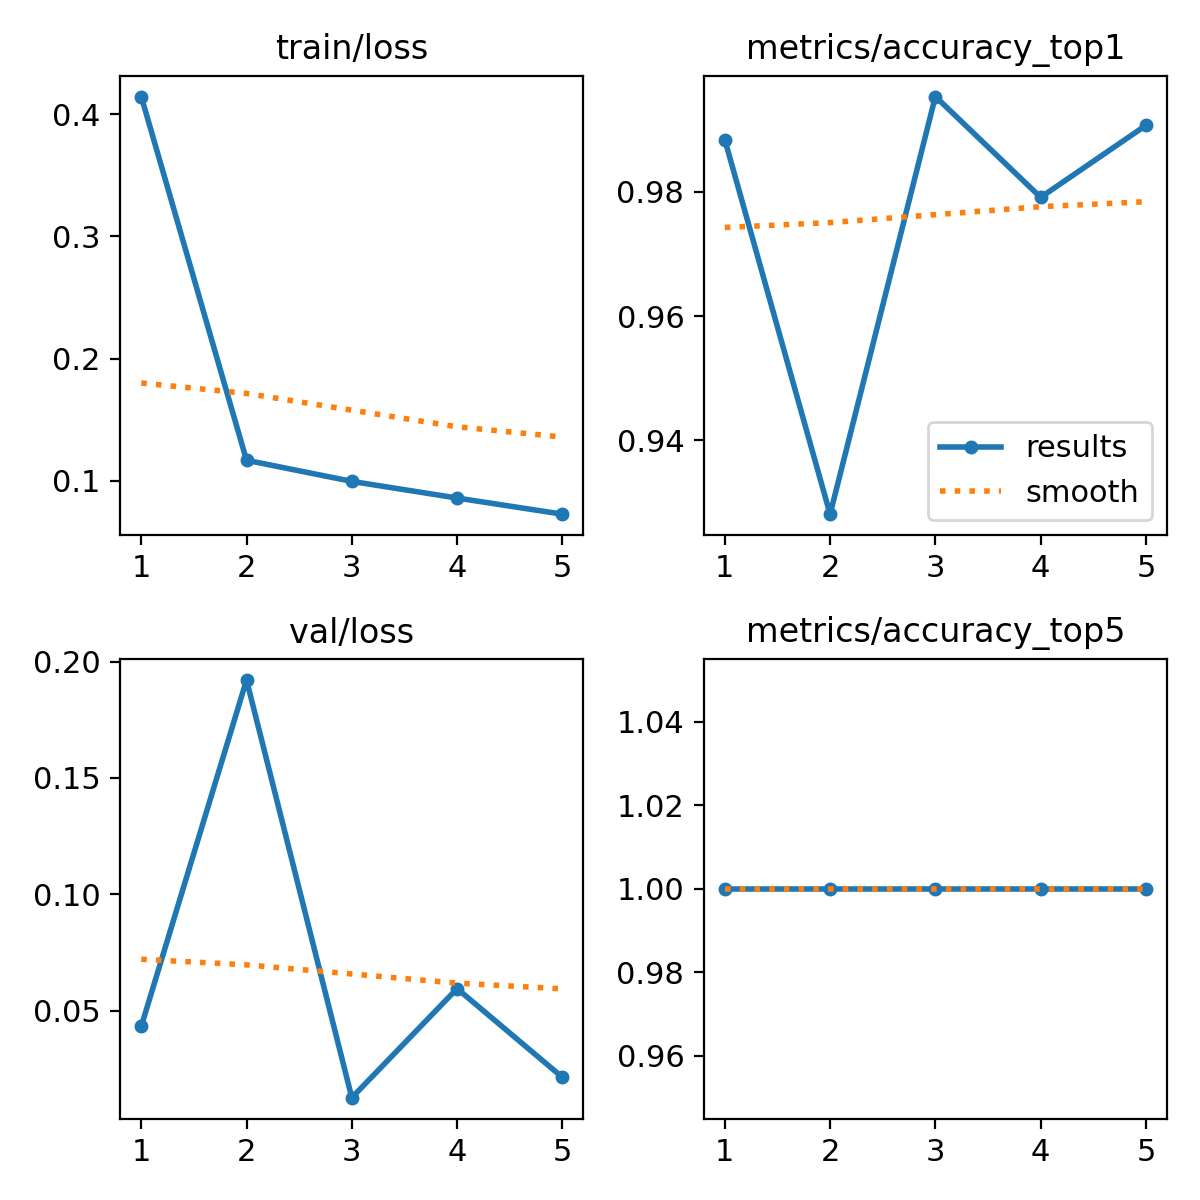

In [9]:
from IPython.display import Image, display
import os

results_png_path = 'runs/classify/train/results.png'

if os.path.exists(results_png_path):
    print("Displaying training loss and accuracy graphs:")
    display(Image(filename=results_png_path))
else:
    print(f"Could not find results image at {results_png_path}. Let's check the contents of the run directory:")
    if os.path.exists('runs/classify/train'):
        print(os.listdir('runs/classify/train'))